In [14]:
import pandas as pd
import os
import pickle

import sys
sys.path.insert(0, "../../..")

from utils.data_processing import add_boundary_column

In [15]:
df = pd.read_csv("../dataset_construction/datasets/processed_aemri75anno.csv")
df["subject"] = df["art_f"].apply(lambda x: os.path.basename(x).split("_")[2])
df = add_boundary_column(df, lang="ae")

In [16]:
distance_df = pd.read_csv("../distinctiveness_calculation/distances_aemri75anno.csv")
surprisal_df = pd.read_csv("../surprisal_calculation/surprisal_aemri75anno.csv")

In [17]:
for col_name in distance_df.columns:
    df[col_name] = distance_df[col_name]
    
for col_name in surprisal_df.columns:
    df[col_name] = surprisal_df[col_name]

In [18]:
with open("../../flexibility_estimation/entropy_estimation/entropies/aemri75anno_art_given_ac.pickle", "rb") as f:
    H_art_given_ac_mdn = pickle.load(f)
with open("../../flexibility_estimation/entropy_estimation/entropies/aemri75anno_ac_given_art.pickle", "rb") as f:
    H_ac_given_art_mdn = pickle.load(f)

In [19]:
flexibility_df = pd.read_csv("../../flexibility_estimation/mutual_information_estimation/res/aemri75anno.csv")
flexibility_df.sort_values(by="flexibility", inplace=True)

In [20]:
phone2flexibility = dict(zip(flexibility_df["phone"], flexibility_df["flexibility"]))
H_art_given_ac_mdn = dict(zip(flexibility_df["phone"], flexibility_df["H_art_given_ac_phone"]))

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='phone', ylabel='H_art_given_ac_phone'>

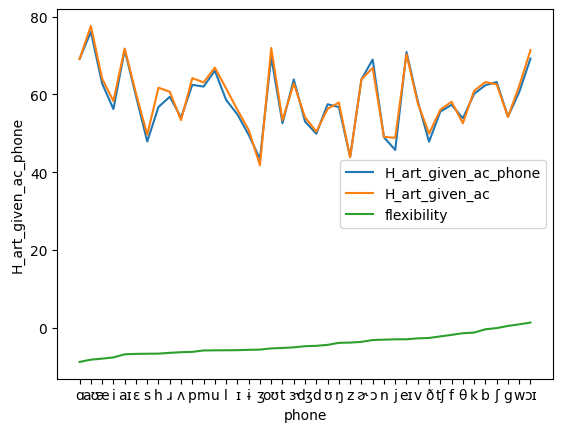

In [22]:
H_art_given_ac_mdn = dict(sorted(H_art_given_ac_mdn.items(), key=lambda item: item[1]))
sns.lineplot(data=flexibility_df, x="phone", y="H_art_given_ac_phone", label="H_art_given_ac_phone")
sns.lineplot(data=flexibility_df, x="phone", y="H_art_given_ac", label="H_art_given_ac")
sns.lineplot(data=flexibility_df, x="phone", y="flexibility", label="flexibility")

In [23]:
df["phone1_H_art_given_ac"] = df.apply(lambda x: H_art_given_ac_mdn.get(x["phone1"], None), axis=1)
df["phone2_H_art_given_ac"] = df.apply(lambda x: H_art_given_ac_mdn.get(x["phone2"], None), axis=1)
df["phone1_flexibility"] = df.apply(lambda x: phone2flexibility.get(x["phone1"], None), axis=1)
df["phone2_flexibility"] = df.apply(lambda x: phone2flexibility.get(x["phone2"], None), axis=1)

In [24]:
df["token_id"] = df.index

In [25]:
# df.to_csv("results_aemri75anno_wide.csv", index=False)

In [26]:
dist_cols = [
    "ac_latent_dist",
    # "ac_raw_dist",
    "art_latent_dist",
    # "art_raw_dist"
]

df_long = df.melt(
    id_vars=[col for col in df.columns if col not in dist_cols],
    value_vars=dist_cols,
    var_name="dist_type",
    value_name="dist"
)

df_long[["modality", "data_space"]] = (
    df_long["dist_type"]
    .str.extract(r"^(ac|art)_(latent|raw)_dist$")
)

df_long = df_long.drop(columns="dist_type")
df_long.to_csv("results_aemri75anno.csv", index=False)